# Resizing FX10 and FX17 data cubes. 
- Due to camera scanning speed, images might look distorted and may need to be resized. 

## Painting dimensions IRL (width x height)
- see `museum_info.txt`

In [2]:
import os

data_path = '/n/archive/labs/hsi-data/serlachius/fx17/reflectance'
print(os.listdir(data_path))

['191.npy', '809a.npy', '230b.npy', '809_full.npy', '458.npy', '230a.npy', '634.npy', '240_2.npy', '597.npy', '809b.npy', '609.npy', '230_full.npy']


In [9]:
from resize import resize_img_cube_nanfriendly
import numpy as np
import matplotlib.pyplot as plt

data_path = '/n/archive/labs/hsi-data/serlachius/fx17/reflectance'
filename = '809_full_resized'
stitched = np.load(f'{data_path}/{filename}.npy')

(8643, 2465, 224)

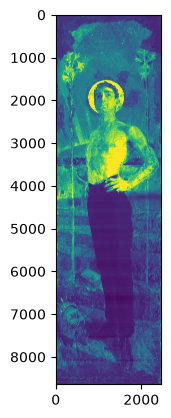

In [10]:
plt.imshow(stitched[..., 100], vmax = 0.5)
stitched.shape

In [5]:
h_irl, w_irl = 138.5, 39.5 # height and width of area in real life

scaler = h_irl / w_irl
new_width  = stitched.shape[1]
new_height = int(new_width * scaler)

resized = resize_img_cube_nanfriendly(stitched, new_height, new_width)

# print(scaler)
# resized = resize_img_cube(canvas_blend, int(blended_h * scaler), blended_w)
print("Original shape:", stitched.shape)
print("Resized shape: ", resized.shape)

Original shape: (10856, 2465, 224)
Resized shape:  (8643, 2465, 224)


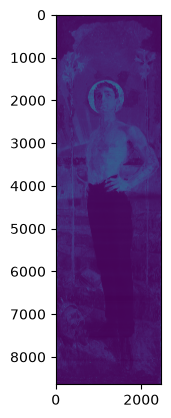

In [6]:
plt.imshow(resized[..., 100])
np.save(f'{filename}_resized.npy', resized)


In [7]:
f'{data_path}/{filename}.npy'

'/n/archive/labs/hsi-data/serlachius/fx17/reflectance/809_full.npy'

In [8]:
np.save(f'{data_path}/{filename}_resized.npy', resized)

# 809_full

- OOM issue, need to resize in pieces if necessary.

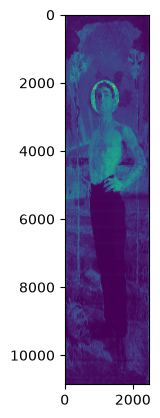

In [3]:
plt.imshow(stitched[:, :, 100], vmin=0, vmax=1)

In [ ]:
from resize import resize_img_cube_nanfriendly
import numpy as np
import matplotlib.pyplot as plt

data_path = '/n/archive/labs/hsi-data/serlachius/fx17/reflectance'
filename = '809_full'
stitched = np.load(f'{data_path}/{filename}.npy')
stitched.shape

# 4.4
w_irl, h_irl = 39.5, 138.5 # height and width of area in real life
scaler = h_irl / w_irl

new_width  = stitched.shape[1]
new_height = int(new_width * scaler)

resized = resize_img_cube_nanfriendly(stitched, new_height, new_width)


# print(scaler)
# resized = resize_img_cube(canvas_blend, int(blended_h * scaler), blended_w)
print("Original shape:", stitched.shape)
print("Resized shape: ", resized.shape)

: 

In [ ]:
import matplotlib.pyplot as plt
# Flip image or not?
resized = np.flip(resized, axis=1)
plt.imshow(resized[:, :, 100], vmin=0, vmax=1)
# print(np.nanmax(resized), np.nanmin(resized))

## Saving the results

In [ ]:
# save_path = '/n/archive/labs/hsi-data/taulukuvaukset_2026/TEMP/data/resized/FX10'
data_path = '/n/archive/labs/hsi-data/serlachius/fx17/reflectance'

name = 'testname'
# np.save(f'{save_path}/{name}.npy', resized)